# Task 04: Social Media Sentiment Toward Brands and Games

<a href="https://colab.research.google.com/github/alhaddad-a/PRODIGY_DS/blob/main/Task_04_Twitter_Sentiment/Task4_Twitter_Sentiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Prodigy InfoTech Data Science Internship

Task: analyze and visualize sentiment patterns in social media data to understand public opinion and attitudes towards specific topics or brands.

Data: [Twitter Entity Sentiment Analysis](https://www.kaggle.com/datasets/jp797498e/twitter-entity-sentiment-analysis) (training file). Each row is a tweet about one of 32 entities (games, tech brands, companies) labeled Positive, Negative, Neutral or Irrelevant.

## 1. Problem statement

A brand or community manager wants to know **how people feel** about their product on social media, how that compares with competitors, and **what people talk about** when they are happy or unhappy.

**Questions**

| # | Question |
|---|---|
| Q1 | What is the overall balance of sentiment? |
| Q2 | Which brands/games have the most positive and most negative opinion? |
| Q3 | Do games, consumer tech and big companies differ? |
| Q4 | Which words drive positive vs negative sentiment, overall and for specific brands? |
| Q5 | Can a model classify sentiment automatically, so this can be tracked on new tweets? |

In [1]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

os.makedirs("images", exist_ok=True)
COLORS = {"Positive": "#2a9d55", "Neutral": "#9aa0a6", "Negative": "#d1495b", "Irrelevant": "#c9b458"}
ORDER = ["Positive", "Neutral", "Negative", "Irrelevant"]
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

def save(fig, name):
    fig.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")

def pct(ax, axis="y"):
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(mticker.PercentFormatter(1.0))

## 2. Load data

In [2]:
url = "https://raw.githubusercontent.com/Prodigy-InfoTech/data-science-datasets/main/Task%204/twitter_training.csv"
raw = pd.read_csv(url, header=None, names=["tweet_id", "entity", "sentiment", "text"])
print(raw.shape)
raw.head(8)

(74682, 4)


,tweet_id,entity,sentiment,text
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...
5,2401,Borderlands,Positive,im getting into borderlands and i can murder y...
6,2402,Borderlands,Positive,So I spent a few hours making something for fu...
7,2402,Borderlands,Positive,So I spent a couple of hours doing something f...


## 3. Data quality

In [3]:
print("Missing text:", raw["text"].isna().sum())
print("Exact duplicate rows:", raw.duplicated().sum())
print("Unique tweet IDs:", raw["tweet_id"].nunique())
print("Rows per tweet ID:", raw.groupby("tweet_id").size().describe()[["min", "max"]].tolist())
same = raw.groupby("tweet_id").agg(s=("sentiment", "nunique"), e=("entity", "nunique"))
print("IDs with more than one label:", (same["s"] > 1).sum(), "| more than one entity:", (same["e"] > 1).sum())

Missing text: 686
Exact duplicate rows: 2700
Unique tweet IDs: 12447
Rows per tweet ID: [6.0, 6.0]
IDs with more than one label: 0 | more than one entity: 0


**The key finding about this dataset:** every tweet ID appears exactly **6 times**. The first row of tweet 2401 above is the original, and the other five are slightly reworded copies (data augmentation). All six share the same label and entity.

This matters in two ways:

1. **For opinion analysis**, counting all six rows would count each tweet six times. I keep **one row per tweet ID** (the longest version, which is usually the original).
2. **For the classifier**, if copies of the same tweet end up in both the training and test sets, the model is tested on text it has already seen, and its accuracy will look far too good. I split by **tweet ID** so all copies stay on the same side (section 8 shows the difference).

I also drop rows with missing text.

In [4]:
data = raw.dropna(subset=["text"]).copy()
data["text"] = data["text"].astype(str)
data["len"] = data["text"].str.len()
tweets = (data.sort_values("len", ascending=False)
              .drop_duplicates("tweet_id")
              .sort_values("tweet_id")
              .reset_index(drop=True))
print(f"All rows (with variants): {len(data):,}")
print(f"Unique tweets for analysis: {len(tweets):,}")

CATEGORY = {
    "Amazon": "Company", "Facebook": "Company", "Google": "Company", "HomeDepot": "Company",
    "Microsoft": "Company", "Verizon": "Company", "johnson&johnson": "Company",
    "Nvidia": "Tech hardware", "PlayStation5(PS5)": "Tech hardware", "Xbox(Xseries)": "Tech hardware",
}
tweets["category"] = tweets["entity"].map(CATEGORY).fillna("Video game")
tweets["category"].value_counts()

All rows (with variants): 73,996
Unique tweets for analysis: 12,447


category
Video game       8556
Company          2734
Tech hardware    1157
Name: count, dtype: int64

### Text cleaning

Tweets contain URLs, @mentions, numbers and punctuation. For word analysis I lowercase, remove URLs and mentions, keep only letters and apostrophes, and remove common stop words ("the", "and", ...). I also remove words that just name the entity (e.g. "borderlands"), so word lists describe opinions rather than topics.

In [5]:
URL = re.compile(r"https?://\S+|www\.\S+")
MENTION = re.compile(r"@\w+")
NON_LETTER = re.compile(r"[^a-z' ]+")
STOP = set(ENGLISH_STOP_WORDS) | {"im", "just", "rt", "amp", "pic", "com", "it's", "i'm", "unk", "twitter", "don't", "isn", "didn", "doesn", "can't", "that's"}

ENTITY_WORDS = set()
for e in tweets["entity"].unique():
    for w in re.findall(r"[a-z0-9]+", re.sub(r"([a-z])([A-Z])", r"\1 \2", e).lower()):
        ENTITY_WORDS.add(w)
ENTITY_WORDS |= {"ps5", "xbox", "cod", "gta", "pubg", "rdr", "csgo", "lol", "apex", "nba", "nfl", "madden", "fifa",
                 "rainbow", "six", "siege", "ghost", "recon", "tom", "clancy", "clancys", "red", "dead", "redemption",
                 "assassins", "creed", "battlefield", "borderlands", "cyberpunk", "overwatch", "fortnite", "hearthstone",
                 "dota", "warcraft", "wow", "nvidia", "verizon", "amazon", "facebook", "google", "microsoft", "johnson",
                 "home", "depot", "homedepot", "league", "legends", "legend", "call", "duty", "black", "ops", "cold", "war",
                 "playstation", "grand", "theft", "auto", "game", "games", "assassin", "assassin's", "eamaddennfl", "nba2k", "cs-go",
                 "battlegrounds", "unknowns", "blackops", "xseries", "series", "johnsonandjohnson"}

def clean(t):
    t = URL.sub(" ", t.lower())
    t = MENTION.sub(" ", t)
    t = NON_LETTER.sub(" ", t)
    return " ".join(w.strip("'") for w in t.split() if len(w.strip("'")) > 2 and w.strip("'") not in STOP)

tweets["clean"] = tweets["text"].map(clean)
tweets["clean_no_entity"] = tweets["clean"].map(lambda s: " ".join(w for w in s.split() if w not in ENTITY_WORDS))
tweets["words"] = tweets["clean"].str.split().str.len()
print("Empty after cleaning:", (tweets["clean"] == "").sum())
tweets[["text", "clean"]].head(5)

Empty after cleaning: 111


,text,clean
0,@amazon wtf .,wtf
1,I mean ’ wa m really disappointed with amazon ...,mean really disappointed amazon sale today ord...
2,"Admit all it subs, you leak out over the innoc...",admit subs leak innocent thought cheeky hot la...
3,@amazon probably some of the worst customer co...,probably worst customer computer service prope...
4,"Now I've just purchased 10 times on her site, ...",i've purchased times site distributed times it...


## 4. Q1: Overall sentiment

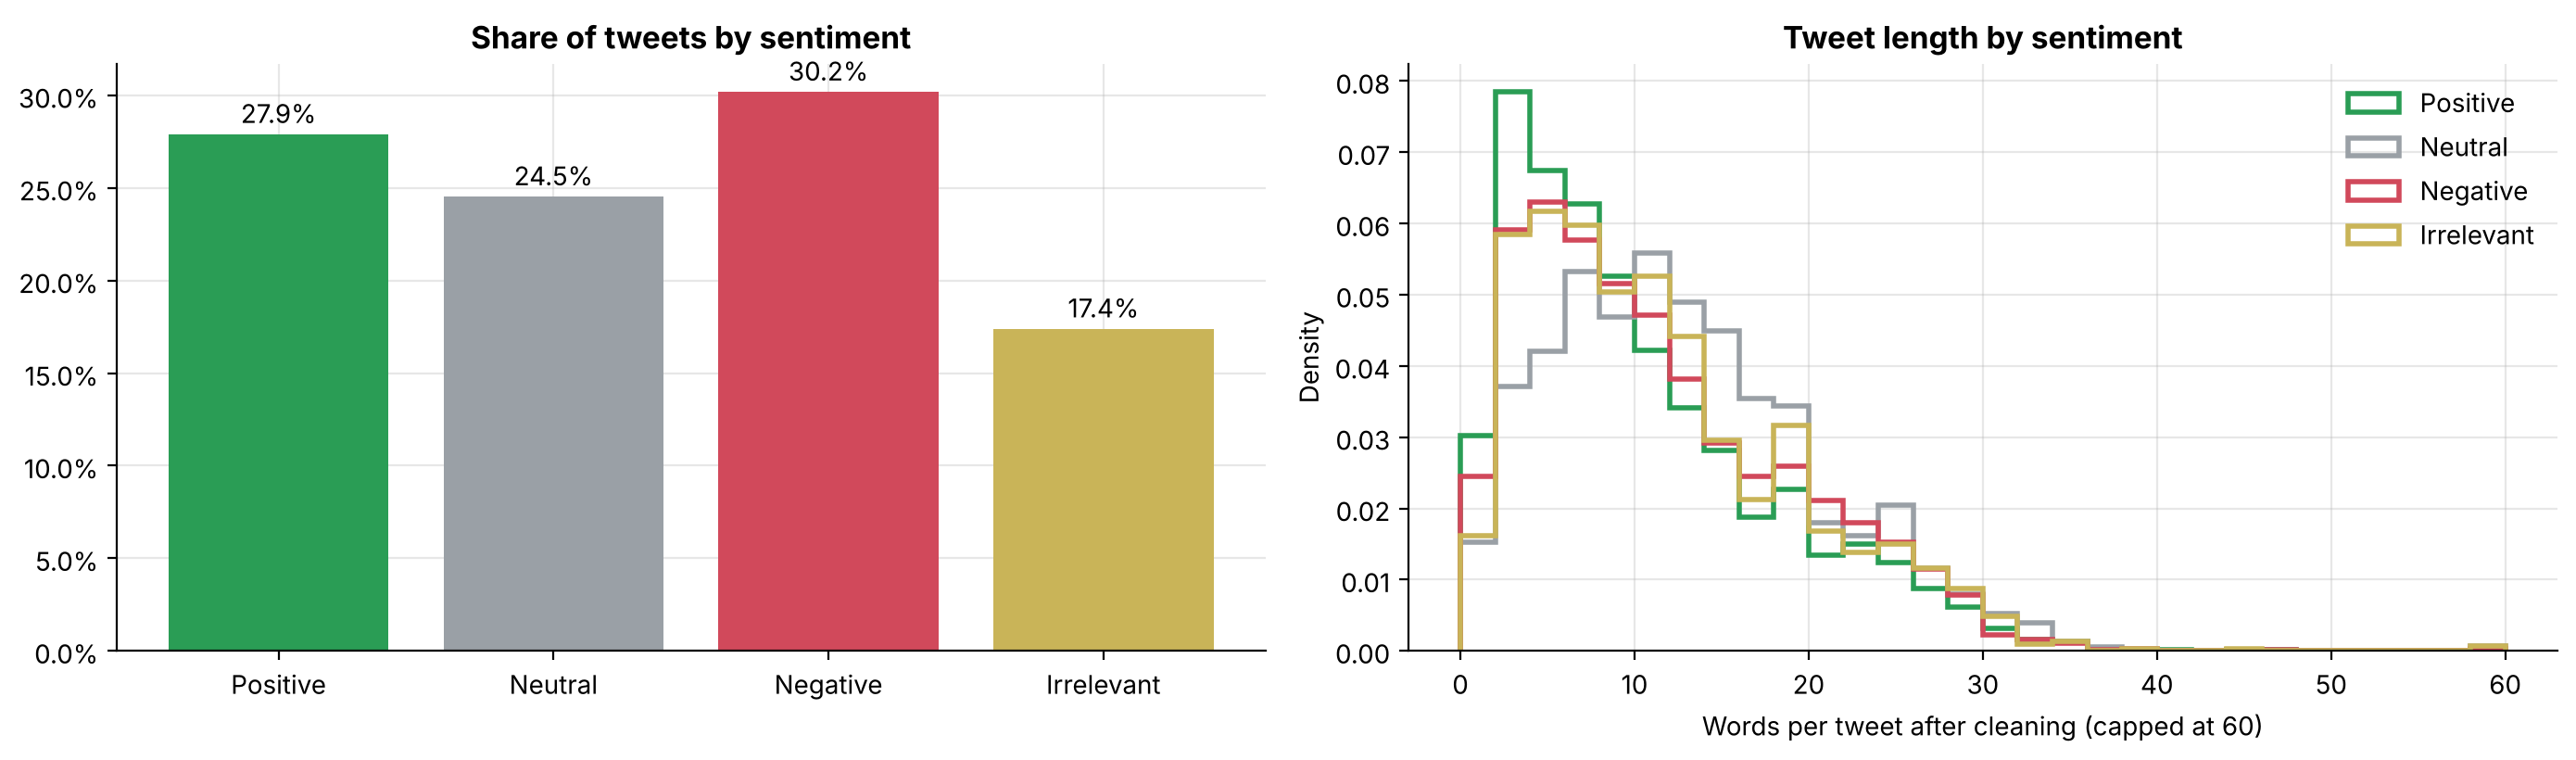

sentiment
Positive      0.279
Neutral       0.245
Negative      0.302
Irrelevant    0.174
Name: proportion, dtype: float64
sentiment
Irrelevant    10.0
Negative       9.0
Neutral       11.0
Positive       8.0
Name: words, dtype: float64


In [6]:
dist = tweets["sentiment"].value_counts(normalize=True).reindex(ORDER)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].bar(dist.index, dist.values, color=[COLORS[s] for s in dist.index])
pct(axes[0])
for c in axes[0].containers:
    axes[0].bar_label(c, labels=[f"{v:.1%}" for v in c.datavalues], padding=2)
axes[0].set_title("Share of tweets by sentiment")

for s in ORDER:
    v = tweets.loc[tweets["sentiment"] == s, "words"].clip(upper=60)
    axes[1].hist(v, bins=30, histtype="step", lw=2, color=COLORS[s], label=s, density=True)
axes[1].set_xlabel("Words per tweet after cleaning (capped at 60)")
axes[1].set_ylabel("Density")
axes[1].legend(frameon=False)
axes[1].set_title("Tweet length by sentiment")
fig.tight_layout()
save(fig, "01_overall_sentiment")
plt.show()
print(dist.round(3))
print(tweets.groupby("sentiment")["words"].median())

## 5. Q2: Sentiment by brand

To compare brands with one number I use **net sentiment** = % positive − % negative (ignoring Neutral and Irrelevant). +100 would mean every opinion is positive, −100 every opinion negative.

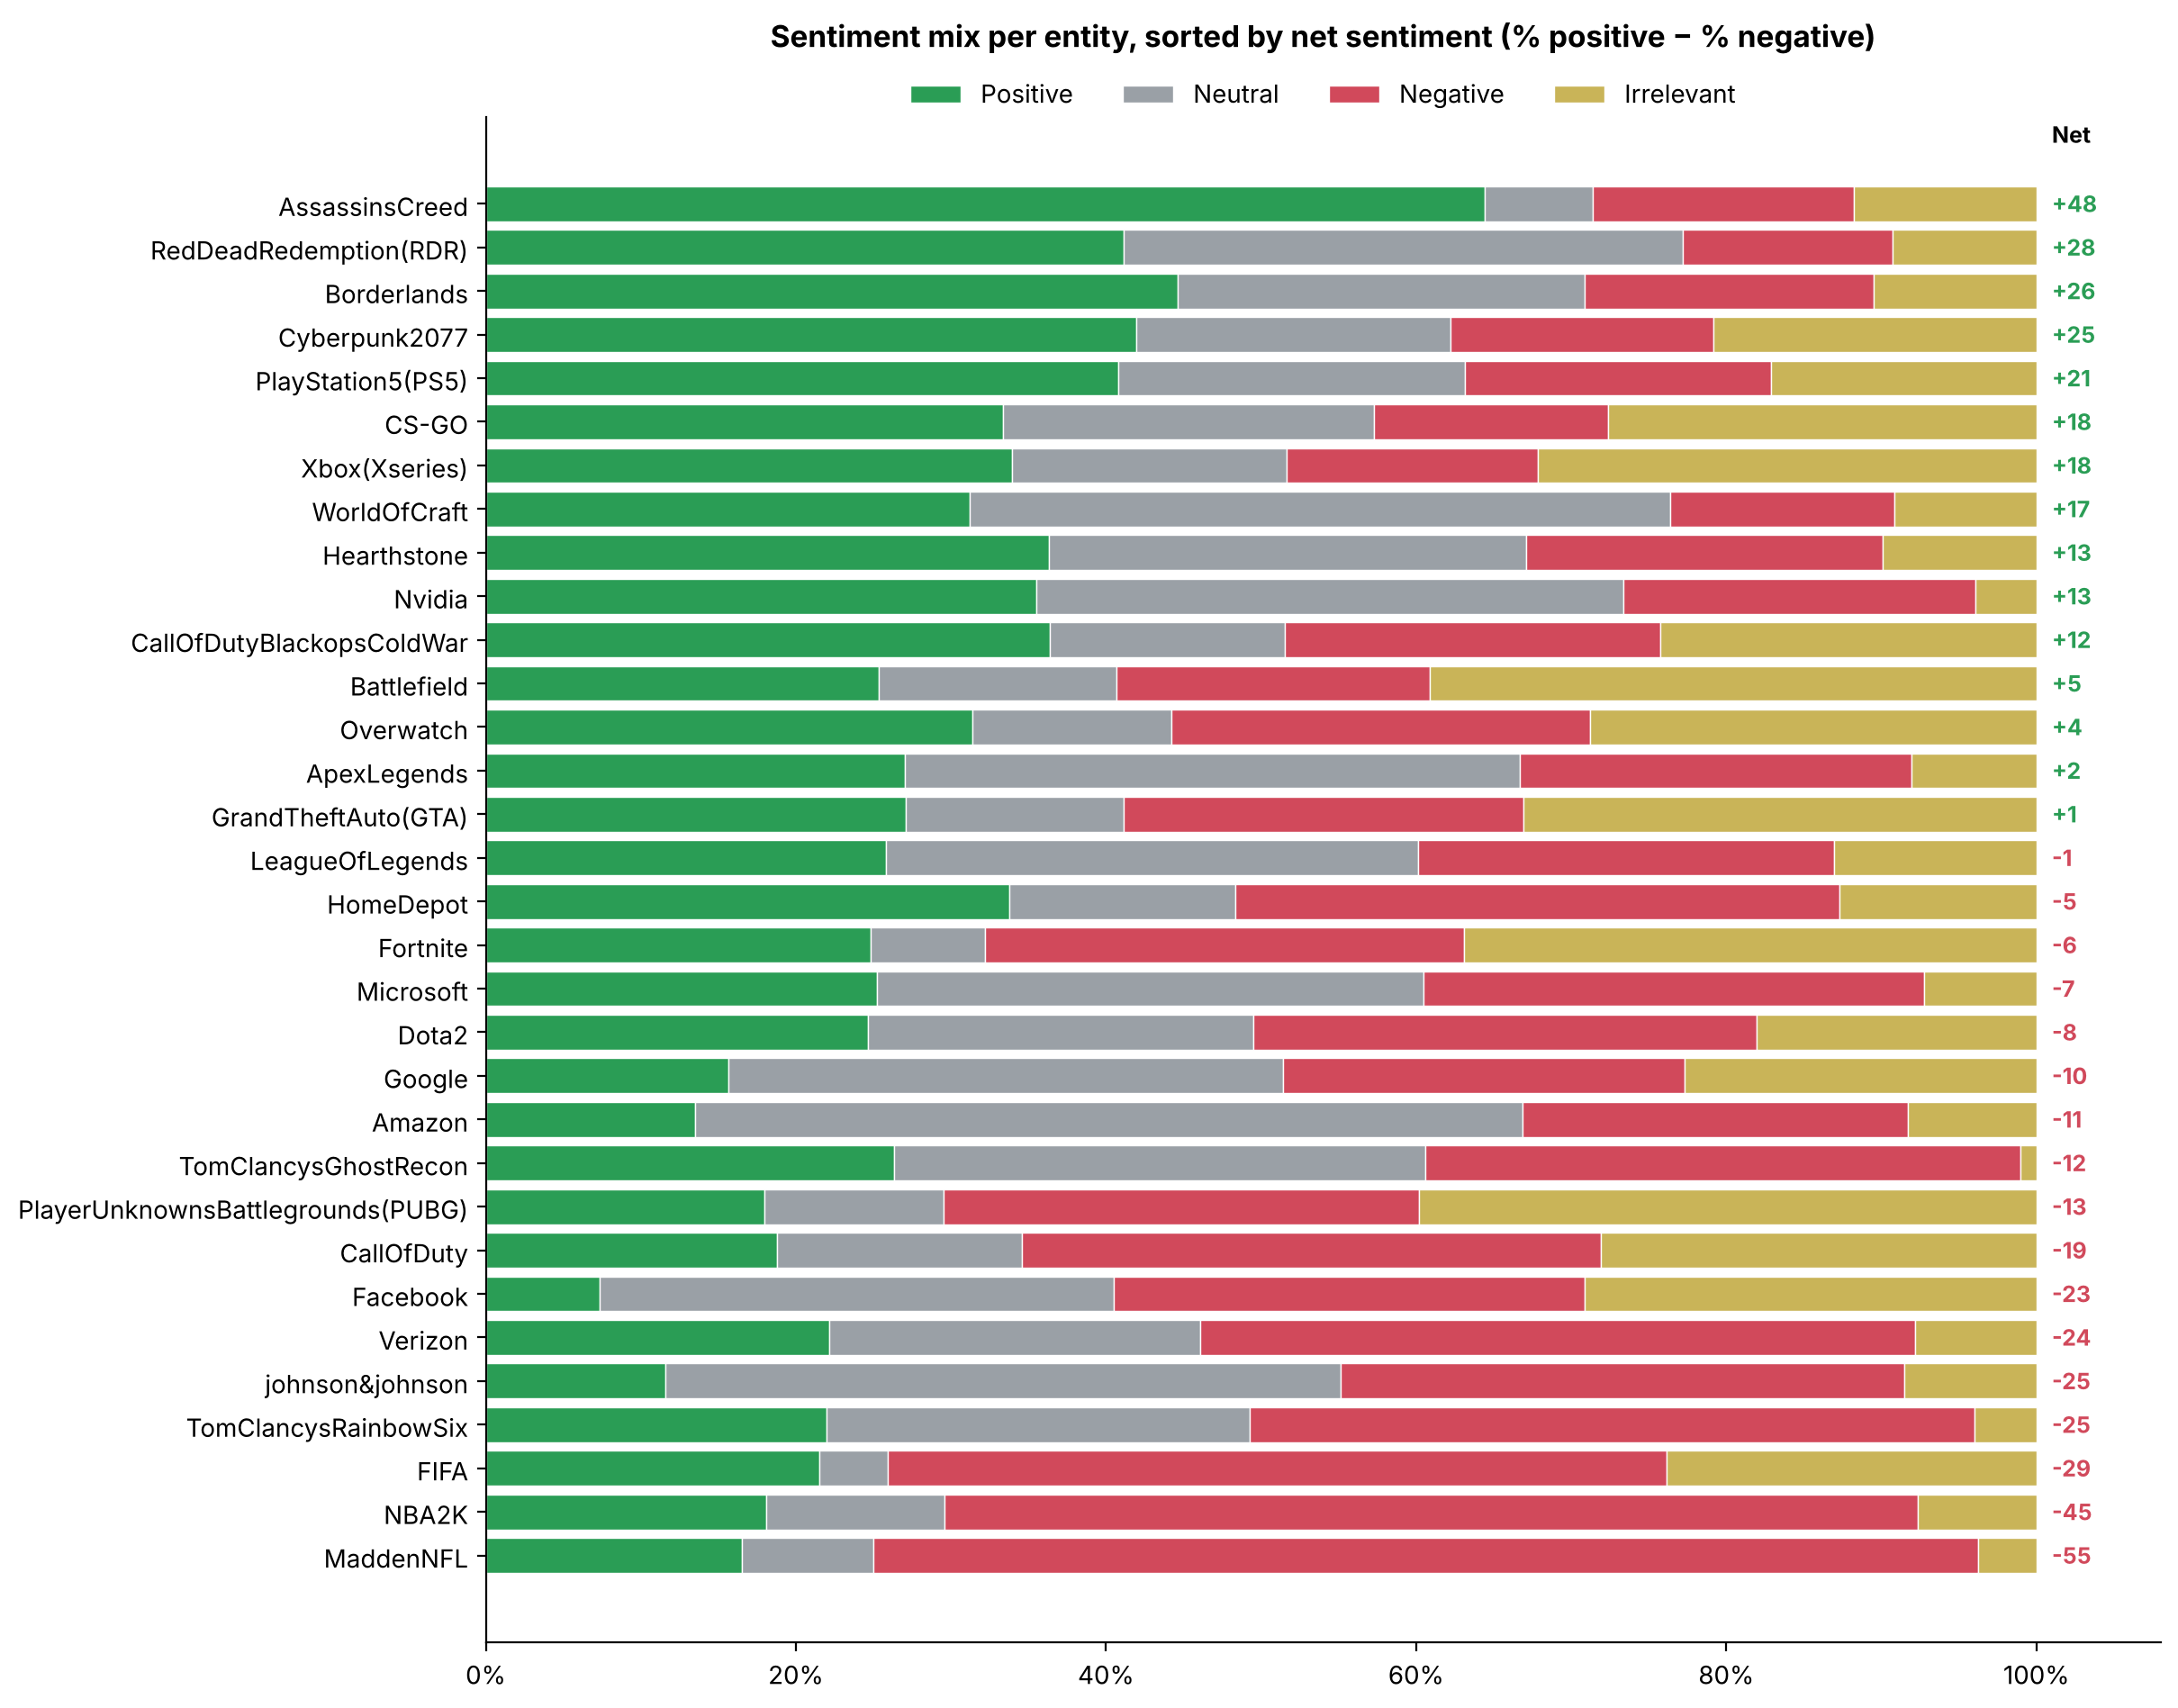

sentiment,Positive,Negative,Neutral,Irrelevant,net,tweets
entity,,,,,,
AssassinsCreed,0.644,0.168,0.070,0.118,0.476,374
RedDeadRedemption(RDR),0.411,0.135,0.361,0.093,0.276,377
Borderlands,0.446,0.186,0.262,0.105,0.260,381
Cyberpunk2077,0.419,0.169,0.203,0.208,0.250,384
PlayStation5(PS5),0.408,0.197,0.223,0.171,0.210,385
CS-GO,0.333,0.151,0.240,0.276,0.182,384
Xbox(Xseries),0.339,0.162,0.177,0.321,0.177,389
WorldOfCraft,0.312,0.145,0.452,0.091,0.168,394
Hearthstone,0.363,0.230,0.308,0.099,0.133,383


In [7]:
share = pd.crosstab(tweets["entity"], tweets["sentiment"], normalize="index")[ORDER]
share["net"] = share["Positive"] - share["Negative"]
share["tweets"] = tweets["entity"].value_counts()
share = share.sort_values("net")

fig, ax = plt.subplots(figsize=(12, 11))
left = np.zeros(len(share))
for s in ORDER:
    ax.barh(share.index, share[s], left=left, color=COLORS[s], label=s, edgecolor="white", lw=0.5)
    left += share[s].values
for i, n in enumerate(share["net"]):
    ax.text(1.01, i, f"{n*100:+.0f}", va="center", fontsize=9,
            color=COLORS["Positive"] if n > 0 else COLORS["Negative"], fontweight="bold")
ax.text(1.01, len(share) - 0.2 + 0.6, "Net", fontsize=9, fontweight="bold")
pct(ax, "x")
ax.set_xlim(0, 1.08)
ax.grid(False)
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.04))
ax.set_title("Sentiment mix per entity, sorted by net sentiment (% positive − % negative)", pad=28)
save(fig, "02_sentiment_by_entity")
plt.show()
share[["Positive", "Negative", "Neutral", "Irrelevant", "net", "tweets"]].sort_values("net", ascending=False).round(3)

## 6. Q3: Games vs tech hardware vs companies

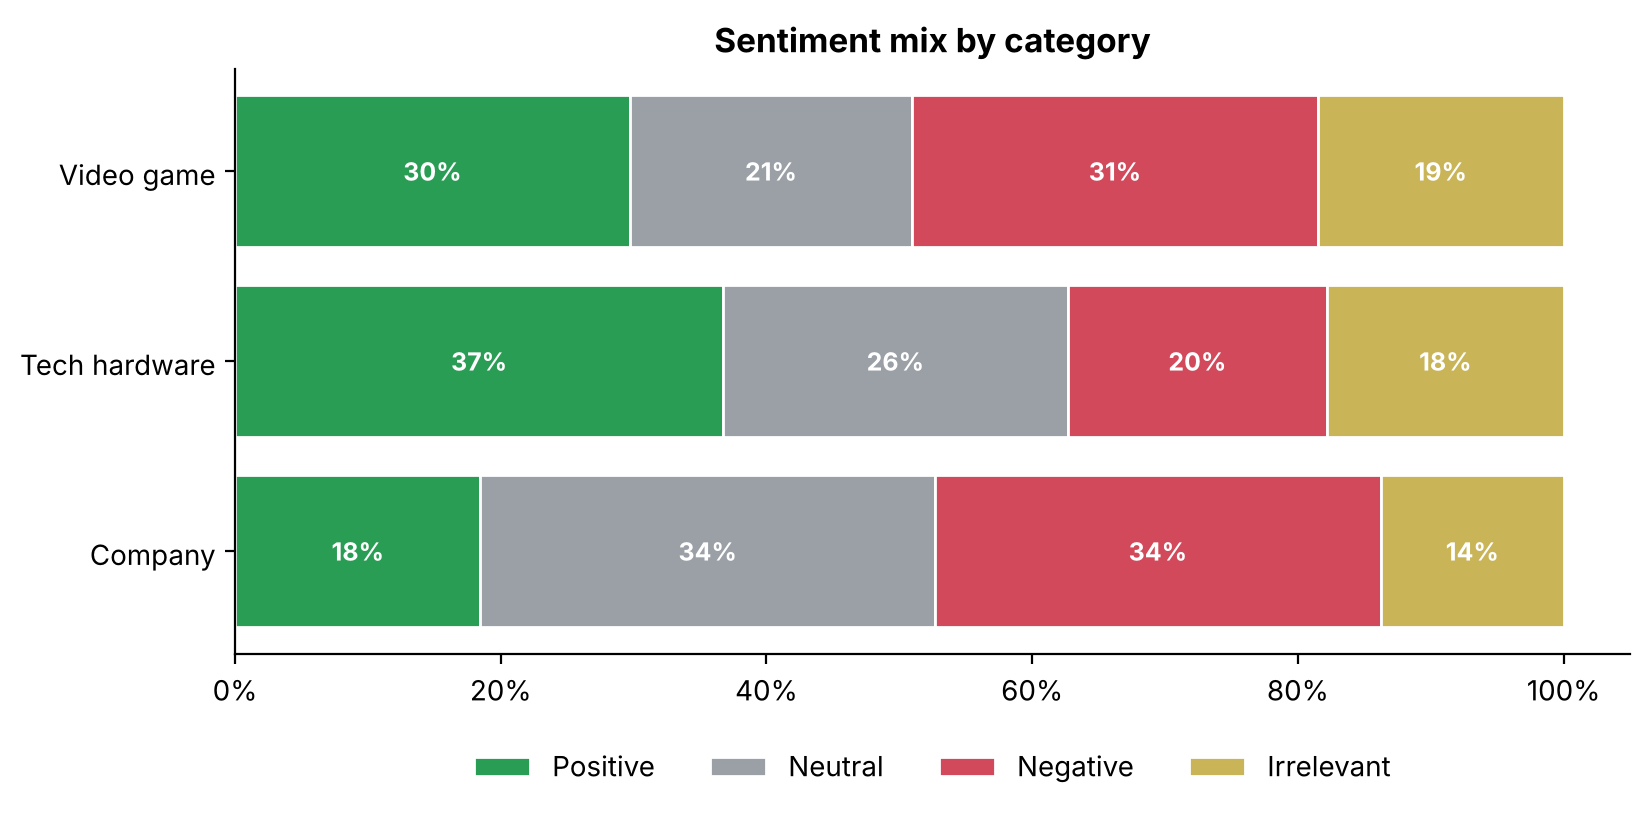

sentiment,Positive,Neutral,Negative,Irrelevant,net
category,,,,,
Company,0.185,0.342,0.336,0.138,-0.151
Tech hardware,0.367,0.259,0.195,0.178,0.172
Video game,0.297,0.212,0.305,0.185,-0.008


In [8]:
cat = pd.crosstab(tweets["category"], tweets["sentiment"], normalize="index")[ORDER]
cat["net"] = cat["Positive"] - cat["Negative"]
fig, ax = plt.subplots(figsize=(9, 3.8))
left = np.zeros(len(cat))
for s in ORDER:
    ax.barh(cat.index, cat[s], left=left, color=COLORS[s], label=s, edgecolor="white")
    for i, (l, v) in enumerate(zip(left, cat[s])):
        if v > 0.06:
            ax.text(l + v / 2, i, f"{v:.0%}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += cat[s].values
pct(ax, "x"); ax.grid(False)
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_title("Sentiment mix by category")
save(fig, "03_sentiment_by_category")
plt.show()
cat.round(3)

## 7. Q4: Which words drive sentiment?

Raw word counts are dominated by common words that appear everywhere. Instead I use the **log-odds ratio**: how much more likely a word is to appear in Positive tweets than in Negative tweets (with smoothing so rare words don't dominate). I only use words that appear at least 30 times.

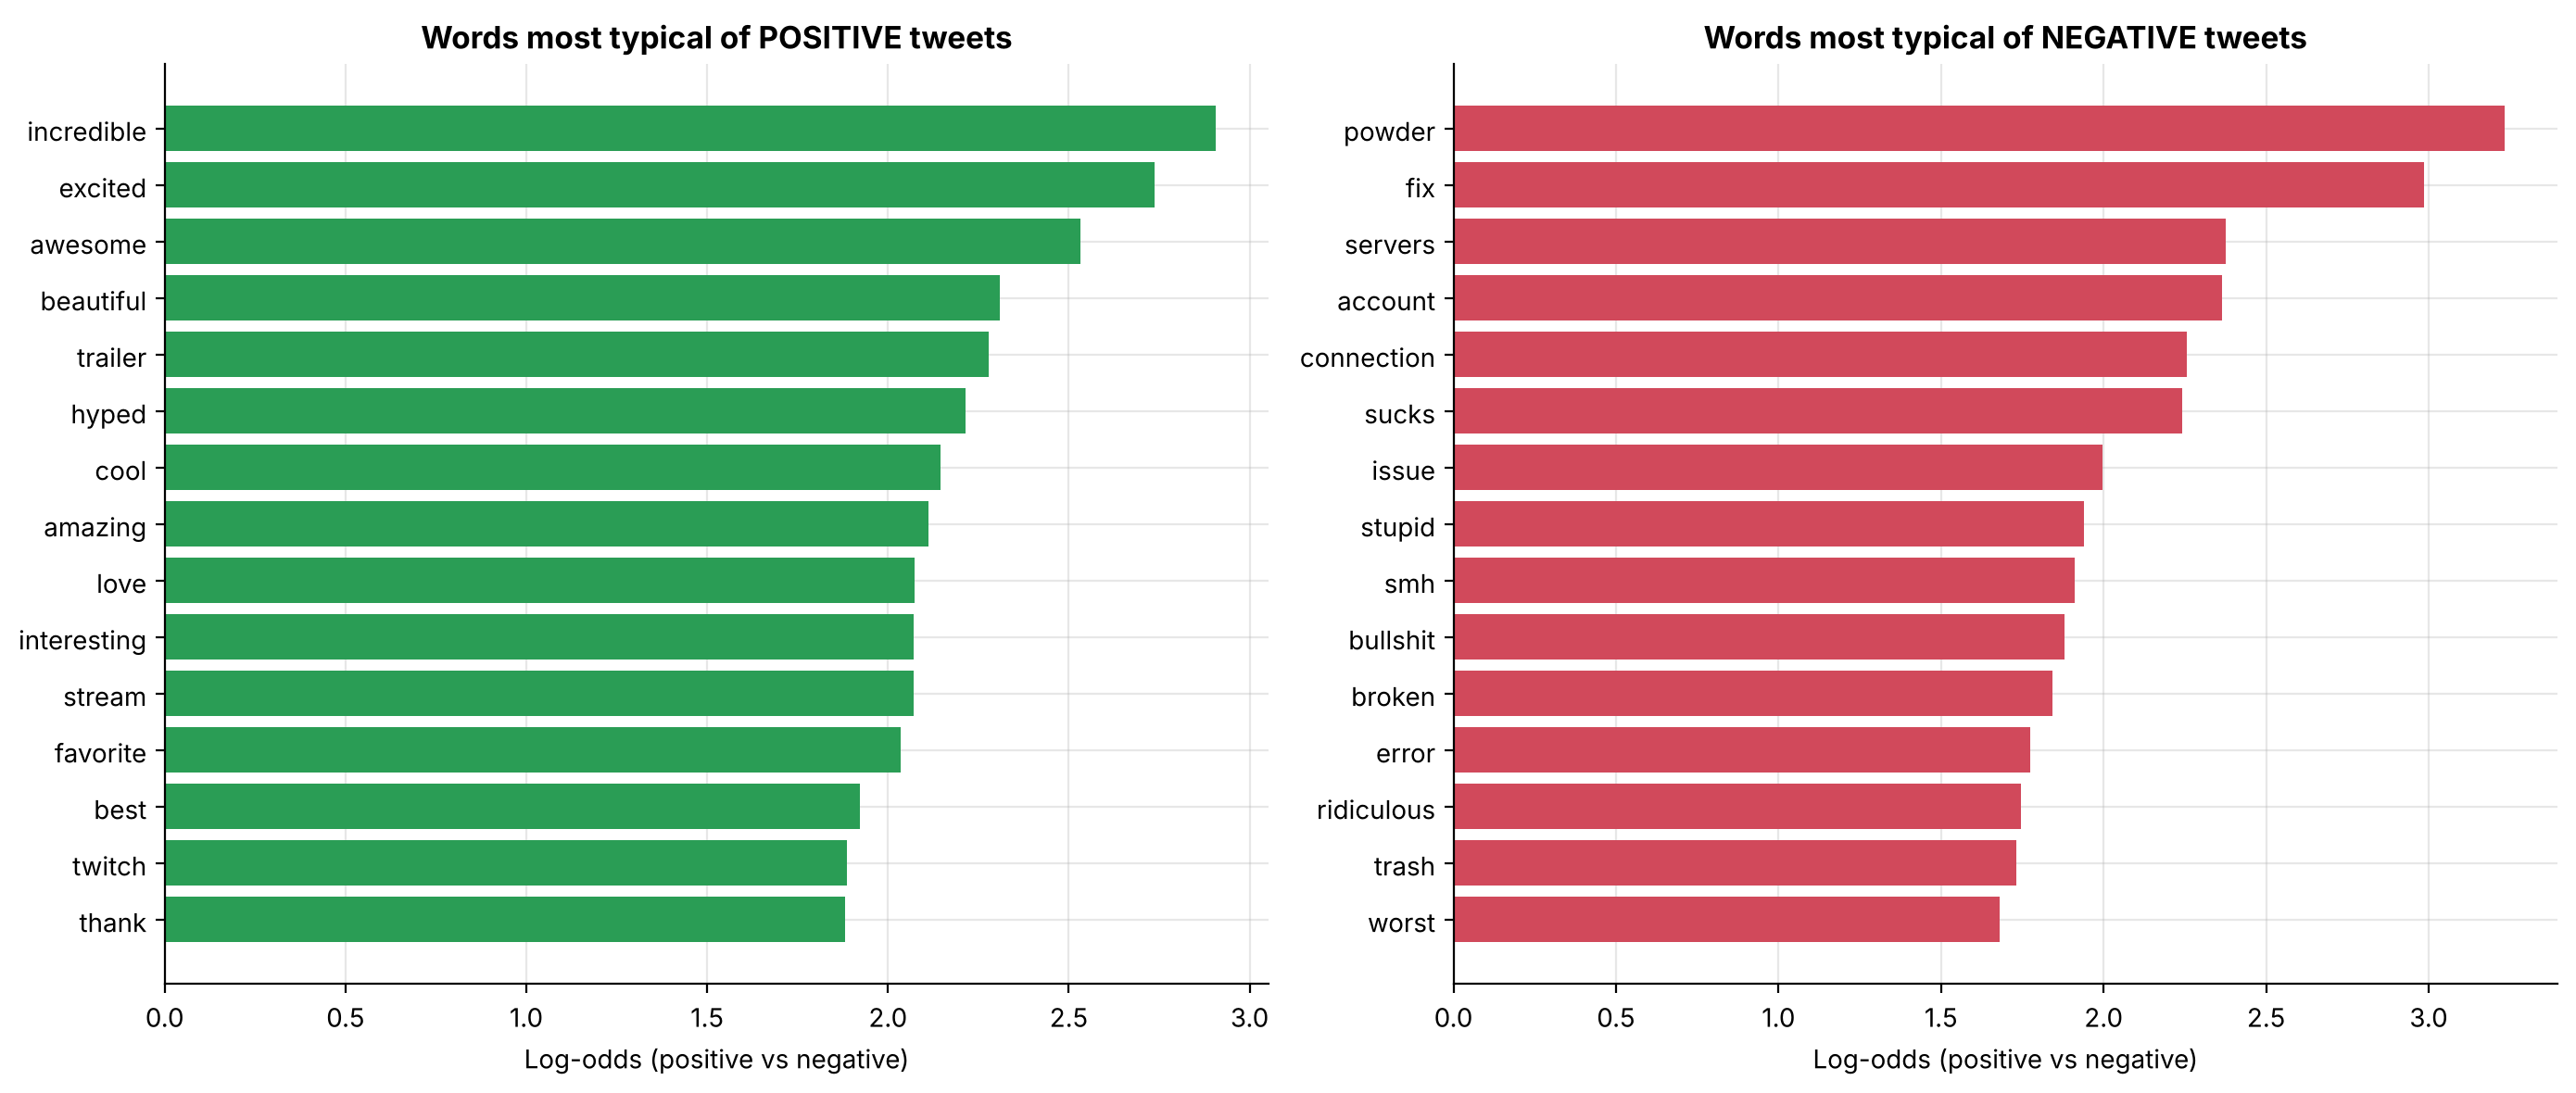

Positive: ['incredible', 'excited', 'awesome', 'beautiful', 'trailer', 'hyped', 'cool', 'amazing', 'love', 'interesting', 'stream', 'favorite', 'best', 'twitch', 'thank']
Negative: ['powder', 'fix', 'servers', 'account', 'connection', 'sucks', 'issue', 'stupid', 'smh', 'bullshit', 'broken', 'error', 'ridiculous', 'trash', 'worst']


In [9]:
def log_odds(text_a, text_b, min_count=30, alpha=1.0):
    ca = Counter(" ".join(text_a).split())
    cb = Counter(" ".join(text_b).split())
    vocab = [w for w in set(ca) | set(cb) if ca[w] + cb[w] >= min_count]
    na, nb = sum(ca.values()), sum(cb.values())
    lo = {w: np.log((ca[w] + alpha) / (na + alpha * len(vocab))) - np.log((cb[w] + alpha) / (nb + alpha * len(vocab)))
          for w in vocab}
    return pd.Series(lo).sort_values()

pos = tweets.loc[tweets["sentiment"] == "Positive", "clean_no_entity"]
neg = tweets.loc[tweets["sentiment"] == "Negative", "clean_no_entity"]
lo = log_odds(pos, neg)
top_pos, top_neg = lo.tail(15), lo.head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(top_pos.index, top_pos.values, color=COLORS["Positive"])
axes[0].set_title("Words most typical of POSITIVE tweets")
axes[1].barh(top_neg.index[::-1], -top_neg.values[::-1], color=COLORS["Negative"])
axes[1].set_title("Words most typical of NEGATIVE tweets")
for ax in axes:
    ax.set_xlabel("Log-odds (positive vs negative)")
fig.tight_layout()
save(fig, "04_words_positive_vs_negative")
plt.show()
print("Positive:", list(top_pos.index[::-1]))
print("Negative:", list(top_neg.index))

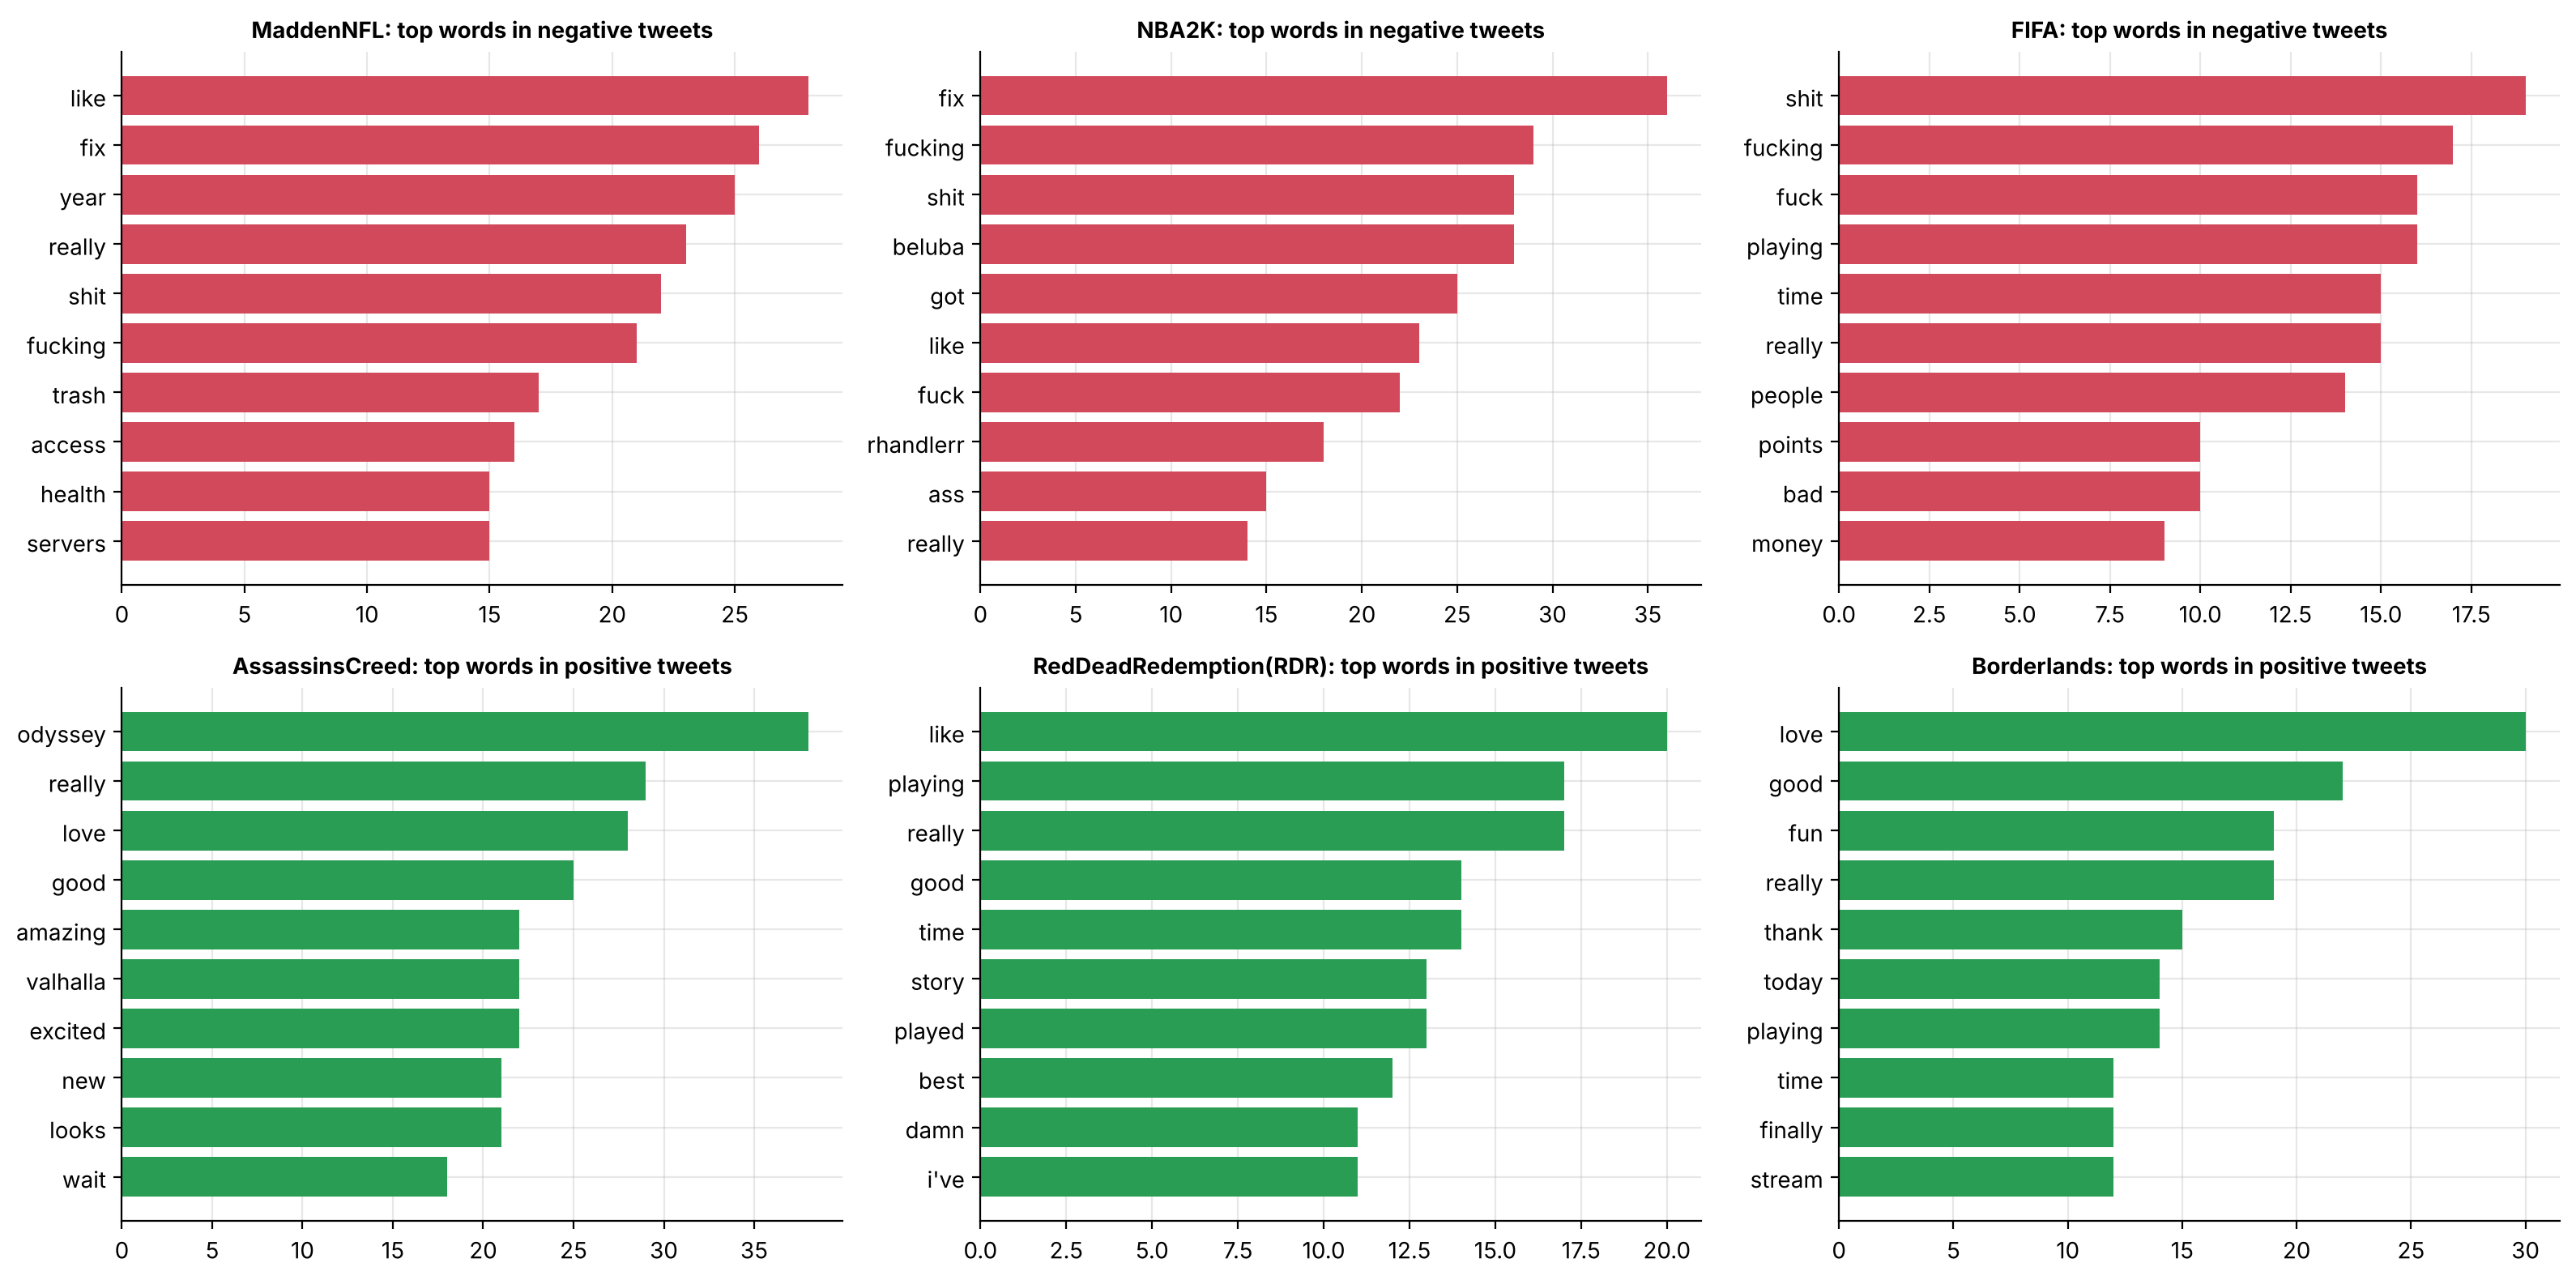

,entity,sentiment,top words
0,MaddenNFL,Negative,"like, fix, year, really, shit, fucking, trash,..."
1,NBA2K,Negative,"fix, fucking, shit, beluba, got, like, fuck, r..."
2,FIFA,Negative,"shit, fucking, fuck, playing, time, really, pe..."
3,AssassinsCreed,Positive,"odyssey, really, love, good, amazing, valhalla..."
4,RedDeadRedemption(RDR),Positive,"like, playing, really, good, time, story, play..."
5,Borderlands,Positive,"love, good, fun, really, thank, today, playing..."


In [10]:
# What do people complain about for the most negative entities, and praise for the most positive?
focus_neg = share.index[:3].tolist()
focus_pos = share.index[-3:][::-1].tolist()
rows = []
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, ent in zip(axes.flat, focus_neg + focus_pos):
    sub = tweets[tweets["entity"] == ent]
    want = "Negative" if ent in focus_neg else "Positive"
    words = Counter(" ".join(sub.loc[sub["sentiment"] == want, "clean_no_entity"]).split()).most_common(10)
    w, c = zip(*words)
    ax.barh(w[::-1], c[::-1], color=COLORS[want])
    ax.set_title(f"{ent}: top words in {want.lower()} tweets", fontsize=10)
    rows.append((ent, want, ", ".join(w[:8])))
fig.tight_layout()
save(fig, "05_entity_words")
plt.show()
pd.DataFrame(rows, columns=["entity", "sentiment", "top words"])

## 8. Q5: Automatic sentiment classifier

To track opinion on new tweets, a model has to label them automatically. I train a **TF-IDF + logistic regression** model, a fast and readable baseline for text.

- **Input:** cleaned tweet text, using single words and word pairs (bigrams)
- **Classes:** Positive, Negative, Neutral, Irrelevant
- **Correct split:** by tweet ID (`GroupShuffleSplit`), using all six variants of training tweets for training (augmentation) and never testing on a variant of a training tweet
- **Comparison:** a naive random row split, to show how much the reworded copies inflate the score

In [11]:
data["clean"] = data["text"].map(clean)
X_text, y_lab, groups = data["clean"], data["sentiment"], data["tweet_id"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, te_idx = next(gss.split(X_text, y_lab, groups))
# evaluate on ONE variant per test tweet (the longest), so each test tweet counts once
test_rows = data.iloc[te_idx].sort_values("len", ascending=False).drop_duplicates("tweet_id")

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=100_000, sublinear_tf=True)
Xtr = vec.fit_transform(X_text.iloc[tr_idx])
Xte = vec.transform(test_rows["clean"])
clf = LogisticRegression(max_iter=2000, C=4)
clf.fit(Xtr, y_lab.iloc[tr_idx])
pred = clf.predict(Xte)
acc = accuracy_score(test_rows["sentiment"], pred)
f1 = f1_score(test_rows["sentiment"], pred, average="macro")
print(f"Train rows: {len(tr_idx):,} | Test tweets (unseen IDs): {len(test_rows):,}")
print(f"Accuracy: {acc:.3f} | Macro F1: {f1:.3f} | Majority-class baseline: {test_rows['sentiment'].value_counts(normalize=True).max():.3f}")
print()
print(classification_report(test_rows["sentiment"], pred, labels=ORDER, digits=3))

Train rows: 59,155 | Test tweets (unseen IDs): 2,490
Accuracy: 0.540 | Macro F1: 0.506 | Majority-class baseline: 0.300

              precision    recall  f1-score   support

    Positive      0.580     0.613     0.596       713
     Neutral      0.483     0.485     0.484       592
    Negative      0.580     0.678     0.625       748
  Irrelevant      0.422     0.259     0.321       437

    accuracy                          0.540      2490
   macro avg      0.516     0.509     0.506      2490
weighted avg      0.529     0.540     0.530      2490



In [12]:
# Naive split for comparison: random rows, so reworded copies of the same tweet land in train AND test
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(X_text, y_lab, test_size=0.2, random_state=42, stratify=y_lab)
vec2 = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=100_000, sublinear_tf=True)
clf2 = LogisticRegression(max_iter=2000, C=4).fit(vec2.fit_transform(Xa_tr), ya_tr)
acc_naive = accuracy_score(ya_te, clf2.predict(vec2.transform(Xa_te)))
print(f"Accuracy with naive random split: {acc_naive:.3f}  <- inflated by near-duplicate tweets")
print(f"Accuracy with tweet-ID split:     {acc:.3f}  <- honest estimate on unseen tweets")

Accuracy with naive random split: 0.903  <- inflated by near-duplicate tweets
Accuracy with tweet-ID split:     0.540  <- honest estimate on unseen tweets


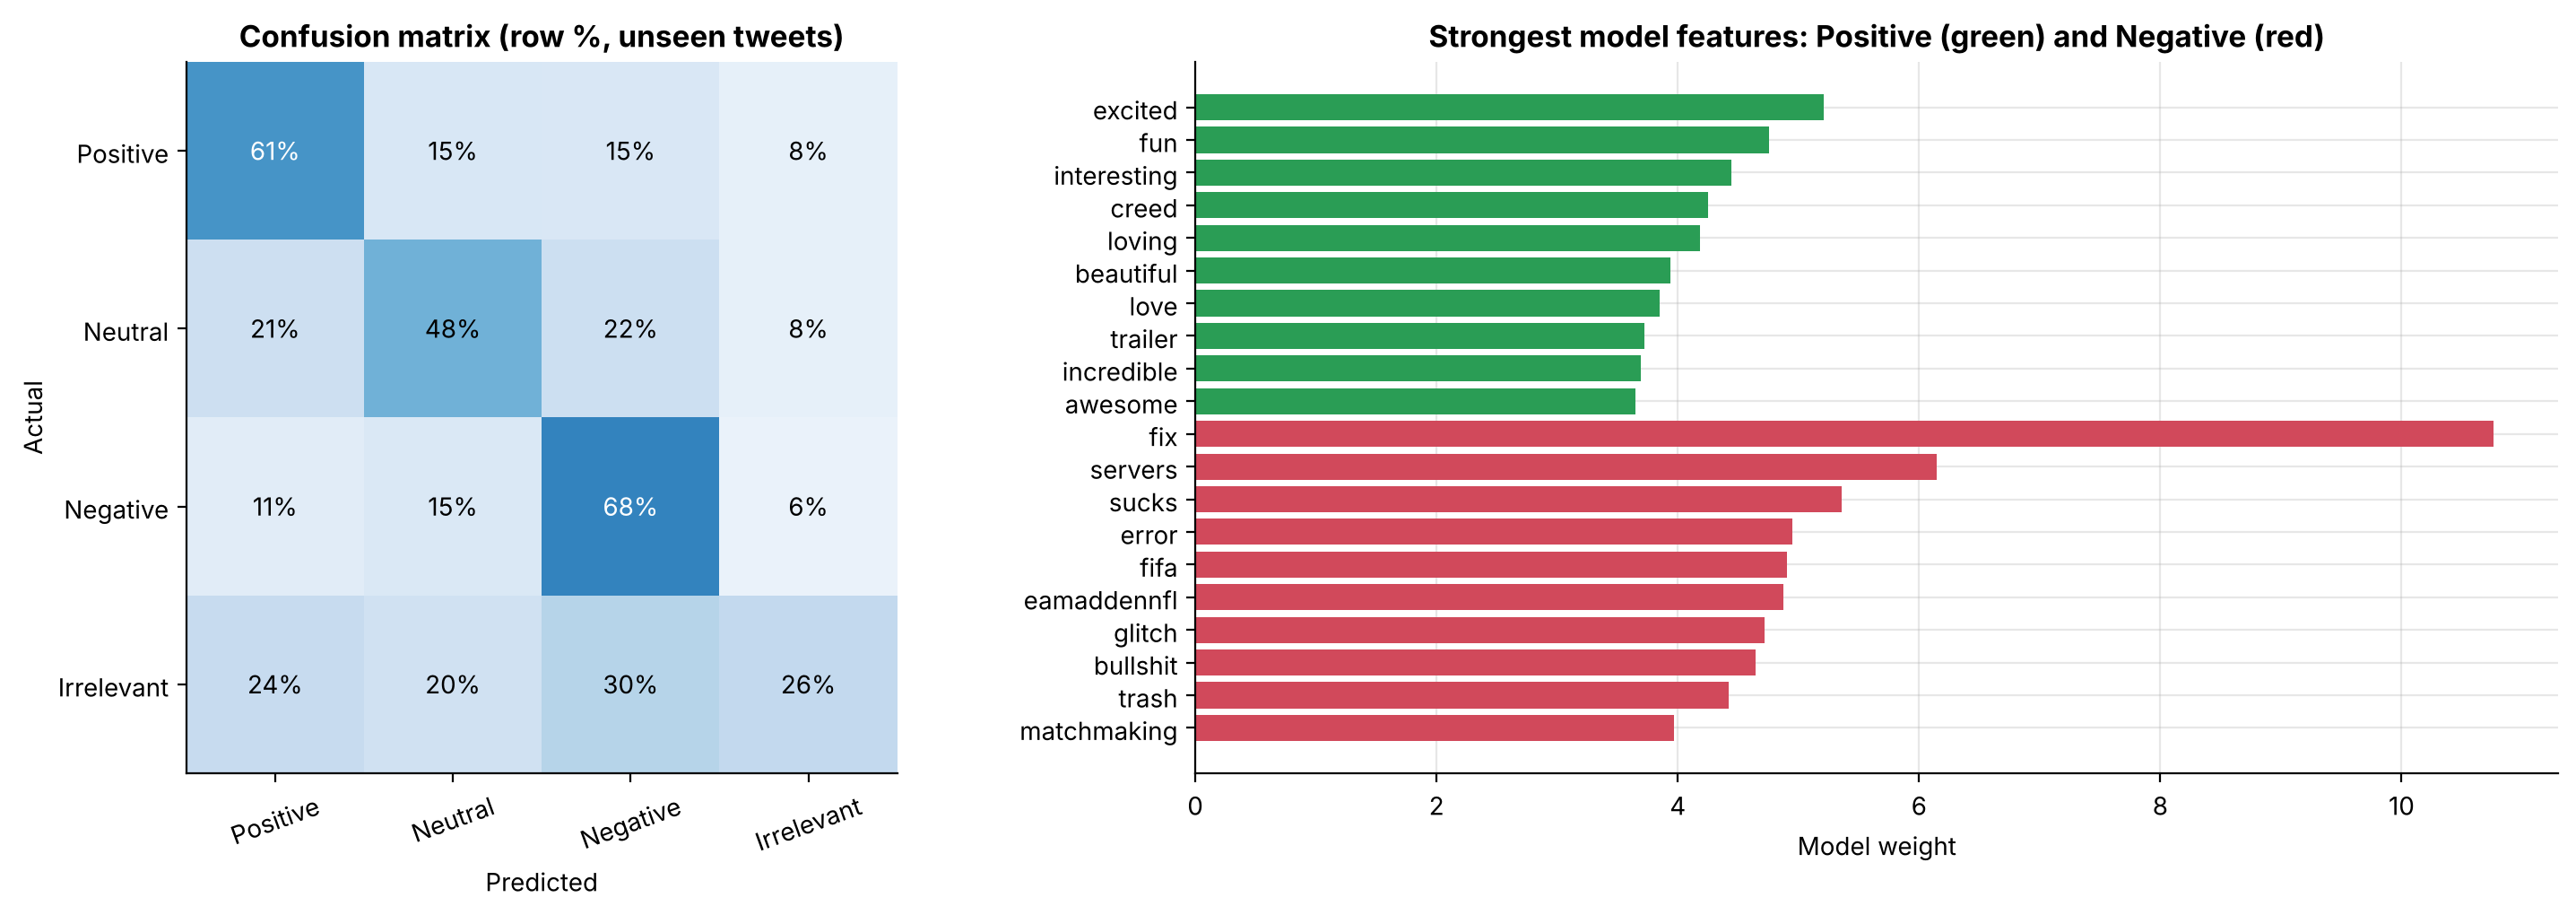

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.4]})
cm = confusion_matrix(test_rows["sentiment"], pred, labels=ORDER, normalize="true")
axes[0].imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        axes[0].text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
axes[0].set_xticks(range(4), ORDER, rotation=20); axes[0].set_yticks(range(4), ORDER)
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].grid(False)
axes[0].set_title("Confusion matrix (row %, unseen tweets)")

coef = pd.DataFrame(clf.coef_, index=clf.classes_, columns=vec.get_feature_names_out())
y0 = 0
labels, vals, cols = [], [], []
for s in ["Positive", "Negative"]:
    top = coef.loc[s].sort_values(ascending=False).head(10)
    labels += list(top.index); vals += list(top.values); cols += [COLORS[s]] * len(top)
axes[1].barh(labels[::-1], vals[::-1], color=cols[::-1])
axes[1].set_xlabel("Model weight")
axes[1].set_title("Strongest model features: Positive (green) and Negative (red)")
fig.tight_layout()
save(fig, "06_classifier")
plt.show()

## 9. Conclusions

1. **Overall opinion is split:** 30.2% negative, 27.9% positive, 24.5% neutral and 17.4% irrelevant (12,447 unique tweets).
2. **Brands:** sports games are the most disliked. **MaddenNFL (net −55), NBA2K (−45) and FIFA (−29)** draw complaints about bugs and fixes, and blame aimed at the developers (EA, Beluba). **Assassin's Creed (+48), Red Dead Redemption (+28), Borderlands (+26) and Cyberpunk 2077 (+25)** are the most liked.
3. **Categories:** tech hardware (PS5, Xbox, Nvidia) is the most positive group (net +17). Big companies are the most negative (net −15) and have the most neutral, news-like tweets (34%). Games overall are balanced but polarized.
4. **Words:** positive tweets are about excitement and enjoyment ("incredible", "excited", "awesome", "beautiful", "trailer", "hyped", "love", "best"). Negative tweets are about **things not working** ("fix", "servers", "account", "connection", "issue", "broken", "error"). "Powder" ranks as the most negative word because of the Johnson & Johnson talc lawsuits. These are concrete, actionable themes.
5. **Model:** on tweets it has never seen, TF-IDF + logistic regression reaches **54.0% accuracy (macro F1 0.506)** vs a 30% majority baseline. A naive random split reports **90.3%**, but only because reworded copies of test tweets were in the training data. That gap is the most important lesson of this task.

**Recommendations:** track net sentiment per brand over time, alert the community team when the negative share rises, and treat "fix / servers / connection / error" complaints as a priority list for game patches and service reliability.

## 10. Limitations

- The tweets were collected and labeled for this dataset, so they are not a random sample of Twitter, and each entity has about the same number of tweets by design.
- "Irrelevant" is the hardest class (26% recall). It is often confused with Negative and Positive, because off-topic tweets can still be emotional.
- Bag-of-words models miss sarcasm and context. A fine-tuned transformer (e.g. Twitter-RoBERTa) is the natural next step.
- There are no dates, so trends over time can't be analyzed.